Celda 1 — Carga de datos, resolución de rutas y motor SQLite en memoria

In [12]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas relativas portables desde notebooks/
BASE_DIR = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
DATA_DIR = os.path.join(BASE_DIR, "data")
DOCS_IMG_DIR = os.path.join(BASE_DIR, "docs", "img")
OUTPUTS_DIR = os.path.join(BASE_DIR, "outputs")
os.makedirs(DOCS_IMG_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

# Carga de datasets
df_orders = pd.read_csv(os.path.join(DATA_DIR, "olist_orders_dataset.csv"))
df_payments = pd.read_csv(os.path.join(DATA_DIR, "olist_order_payments_dataset.csv"))
df_customers = pd.read_csv(os.path.join(DATA_DIR, "olist_customers_dataset.csv"))

# Carga en base de datos relacional SQLite en memoria para auditoría SQL
conn = sqlite3.connect(":memory:")
df_orders.to_sql("orders", conn, index=False, if_exists="replace")
df_payments.to_sql("payments", conn, index=False, if_exists="replace")
df_customers.to_sql("customers", conn, index=False, if_exists="replace")

print(f"Órdenes totales: {len(df_orders):,} | Registros de pago: {len(df_payments):,} | Clientes: {len(df_customers):,}")

Órdenes totales: 99,441 | Registros de pago: 103,886 | Clientes: 99,441


Celda 2 — Pruebas Contables 1 y 2: Integridad de Ingresos y Contingencias por Reembolso

In [13]:
# Prueba 1A: Entregas sin pago
q_sin_pago = """
SELECT o.order_id, o.customer_id, o.order_status, o.order_purchase_timestamp, o.order_delivered_customer_date
FROM orders o
LEFT JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered' AND p.order_id IS NULL;
"""
df_sin_pago = pd.read_sql_query(q_sin_pago, conn)

# Prueba 1B: Pagos nulos o <= 0
q_pagos_cero = """
SELECT p.order_id, o.order_status, p.payment_sequential, p.payment_type, p.payment_value
FROM payments p
LEFT JOIN orders o ON p.order_id = o.order_id
WHERE p.payment_value IS NULL OR p.payment_value <= 0;
"""
df_pagos_cero = pd.read_sql_query(q_pagos_cero, conn)

# Prueba 2: Órdenes canceladas o no disponibles con cobro registrado
q_cancelados_cobrados = """
SELECT o.order_status,
       COUNT(DISTINCT o.order_id) AS ordenes_afectadas,
       COUNT(p.payment_sequential) AS transacciones_pago,
       ROUND(SUM(p.payment_value), 2) AS monto_expuesto_reembolso
FROM orders o
INNER JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status IN ('canceled', 'unavailable') AND p.payment_value > 0
GROUP BY o.order_status
ORDER BY monto_expuesto_reembolso DESC;
"""
df_cancelados_cobrados = pd.read_sql_query(q_cancelados_cobrados, conn)

# Detalle individual de órdenes canceladas con cobro para el reporte Excel
q_detalle_cancelados = """
SELECT o.order_id, o.order_status, o.order_purchase_timestamp,
       ROUND(SUM(p.payment_value), 2) AS monto_cobrado
FROM orders o
INNER JOIN payments p ON o.order_id = p.order_id
WHERE o.order_status IN ('canceled', 'unavailable') AND p.payment_value > 0
GROUP BY o.order_id, o.order_status, o.order_purchase_timestamp
ORDER BY monto_cobrado DESC;
"""
df_detalle_cancelados = pd.read_sql_query(q_detalle_cancelados, conn)

print(f"1A. Entregas sin pago: {len(df_sin_pago)}")
print(f"1B. Pagos <= 0: {len(df_pagos_cero)}")
display(df_cancelados_cobrados)

1A. Entregas sin pago: 1
1B. Pagos <= 0: 9


,order_status,ordenes_afectadas,transacciones_pago,monto_expuesto_reembolso
0,canceled,622,661,143255.60
1,unavailable,609,649,126479.51


Celda 3 — Corte Patrimonial por Cierre Mensual y Mix de Cobros Brutos (GMV)

Pico máximo de anticipos al cierre: 2018-03 -> 3,778 órdenes | R$ 650,720.07
Saldo promedio al cierre mensual: R$ 284,249.49


,cierre_mensual,ordenes_pendientes_cierre,saldo_anticipos_brl
10,2017-10,1490,256206.25
11,2017-11,3969,636429.84
12,2017-12,2439,402258.78
13,2018-01,2833,478774.38
14,2018-02,3519,561967.22
15,2018-03,3778,650720.07
16,2018-04,2567,459533.58
17,2018-05,2396,444434.16
18,2018-06,1661,288465.18
19,2018-07,1869,346461.72


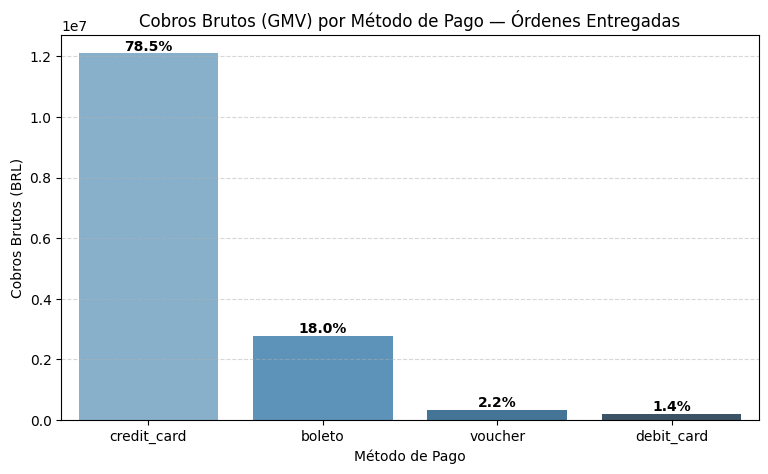

In [14]:
# Prueba 3: Saldo patrimonial de anticipos al cierre de cada mes (no sumable entre períodos)
q_corte_mensual = """
WITH meses AS (
    SELECT DISTINCT strftime('%Y-%m', order_approved_at) AS mes
    FROM orders WHERE order_approved_at IS NOT NULL
),
pagos AS (
    SELECT order_id, ROUND(SUM(payment_value), 2) AS total_cobrado
    FROM payments GROUP BY order_id
)
SELECT m.mes AS cierre_mensual,
       COUNT(o.order_id) AS ordenes_pendientes_cierre,
       ROUND(SUM(p.total_cobrado), 2) AS saldo_anticipos_brl
FROM meses m
INNER JOIN orders o
    ON o.order_status = 'delivered'
   AND date(o.order_approved_at) <= date(m.mes || '-01', '+1 month', '-1 day')
   AND date(o.order_delivered_customer_date) > date(m.mes || '-01', '+1 month', '-1 day')
INNER JOIN pagos p ON p.order_id = o.order_id
GROUP BY m.mes
ORDER BY m.mes;
"""
df_corte_mensual = pd.read_sql_query(q_corte_mensual, conn)
pico_cierre = df_corte_mensual.loc[df_corte_mensual["saldo_anticipos_brl"].idxmax()]
print(f"Pico máximo de anticipos al cierre: {pico_cierre['cierre_mensual']} -> {int(pico_cierre['ordenes_pendientes_cierre']):,} órdenes | R$ {pico_cierre['saldo_anticipos_brl']:,.2f}")
print(f"Saldo promedio al cierre mensual: R$ {df_corte_mensual['saldo_anticipos_brl'].mean():,.2f}")
display(df_corte_mensual.tail(12))

# Mix de cobros brutos (GMV) sobre órdenes entregadas
q_mix_pagos = """
SELECT p.payment_type,
       ROUND(SUM(p.payment_value), 2) AS cobro_bruto_brl,
       ROUND(SUM(p.payment_value) * 100.0 / SUM(SUM(p.payment_value)) OVER (), 2) AS participacion_pct
FROM payments p
INNER JOIN orders o ON p.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY p.payment_type
ORDER BY cobro_bruto_brl DESC;
"""
df_mix_pagos = pd.read_sql_query(q_mix_pagos, conn)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=df_mix_pagos, x="payment_type", y="cobro_bruto_brl", palette="Blues_d", hue="payment_type", legend=False)
for idx, row in df_mix_pagos.iterrows():
    ax.text(idx, row["cobro_bruto_brl"], f"{row['participacion_pct']:.1f}%", ha="center", va="bottom", fontweight="bold")
plt.title("Cobros Brutos (GMV) por Método de Pago — Órdenes Entregadas")
plt.xlabel("Método de Pago")
plt.ylabel("Cobros Brutos (BRL)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.savefig(os.path.join(DOCS_IMG_DIR, "grafico_metodos_pago.png"), dpi=150, bbox_inches="tight")
plt.show()

Celda 4 — Ranking de Incumplimiento de Plazo (SLA) con Filtro Muestral ($n \ge 100$)

,estado,total_entregas,lead_time_promedio_dias,entregas_fuera_plazo,tasa_fuera_plazo_pct,demoras_criticas_30d,tasa_demora_critica_pct
0,AL,397,24.0,85,21.41,96,24.18
1,MA,717,21.1,125,17.43,105,14.64
2,SE,335,21.0,51,15.22,50,14.93
3,PI,476,19.0,66,13.87,44,9.24
4,CE,1279,20.8,176,13.76,178,13.92
6,BA,3256,18.9,396,12.16,355,10.90
7,RJ,12350,14.8,1495,12.11,1079,8.74
8,PA,946,23.3,106,11.21,196,20.72
9,ES,1995,15.3,214,10.73,101,5.06
10,PB,517,20.0,54,10.44,73,14.12


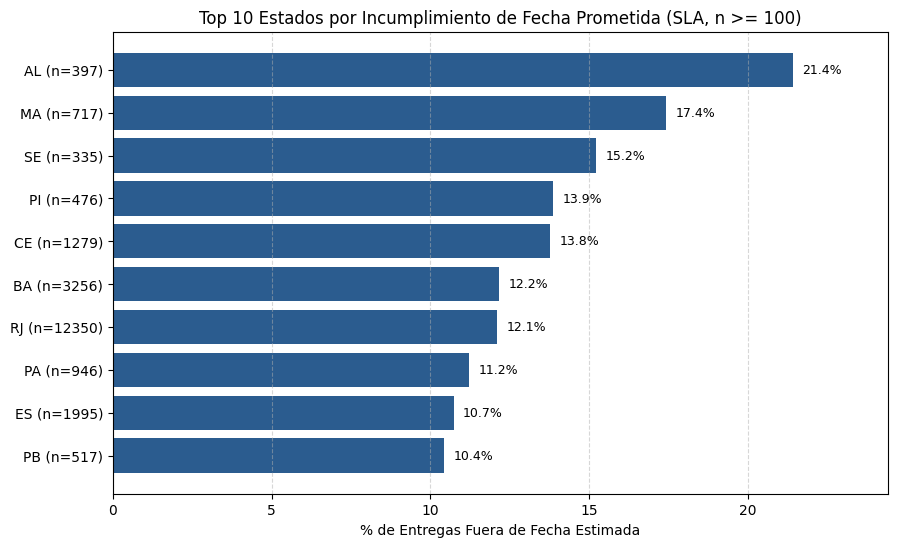

In [15]:
q_sla_estados = """
WITH metricas_entrega AS (
    SELECT c.customer_state AS estado,
           o.order_id,
           CAST(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp) AS INTEGER) AS lead_time_dias,
           CASE WHEN CAST(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp) AS INTEGER) > 30 THEN 1 ELSE 0 END AS es_demora_critica,
           CASE WHEN date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date) THEN 1 ELSE 0 END AS es_fuera_de_plazo
    FROM orders o
    INNER JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
)
SELECT estado,
       COUNT(order_id) AS total_entregas,
       ROUND(AVG(lead_time_dias), 1) AS lead_time_promedio_dias,
       SUM(es_fuera_de_plazo) AS entregas_fuera_plazo,
       ROUND(SUM(es_fuera_de_plazo) * 100.0 / COUNT(order_id), 2) AS tasa_fuera_plazo_pct,
       SUM(es_demora_critica) AS demoras_criticas_30d,
       ROUND(SUM(es_demora_critica) * 100.0 / COUNT(order_id), 2) AS tasa_demora_critica_pct
FROM metricas_entrega
GROUP BY estado
ORDER BY tasa_fuera_plazo_pct DESC, total_entregas DESC;
"""
df_sla_estados = pd.read_sql_query(q_sla_estados, conn)

# Filtro n >= 100 para visualización robusta (el Excel conserva los 27 estados)
df_sla_significativo = df_sla_estados[df_sla_estados["total_entregas"] >= 100].copy()
display(df_sla_significativo.head(10))

top10_sla = df_sla_significativo.head(10).sort_values("tasa_fuera_plazo_pct", ascending=True).copy()
top10_sla["etiqueta"] = top10_sla["estado"] + " (n=" + top10_sla["total_entregas"].astype(str) + ")"

plt.figure(figsize=(10, 6))
bars = plt.barh(top10_sla["etiqueta"], top10_sla["tasa_fuera_plazo_pct"], color="#2b5c8f")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=9)
plt.title("Top 10 Estados por Incumplimiento de Fecha Prometida (SLA, n >= 100)")
plt.xlabel("% de Entregas Fuera de Fecha Estimada")
plt.xlim(0, top10_sla["tasa_fuera_plazo_pct"].max() + 3)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.savefig(os.path.join(DOCS_IMG_DIR, "grafico_demoras_geograficas.png"), dpi=150, bbox_inches="tight")
plt.show()

Celda 5 — Exportación del Reporte Multi-Hoja (incluyendo detalle 1A y 1B)

In [16]:
total_entregadas = int(df_sla_estados["total_entregas"].sum())
total_demoras_30d = int(df_sla_estados["demoras_criticas_30d"].sum())
total_fuera_plazo = int(df_sla_estados["entregas_fuera_plazo"].sum())
tasa_global_30d = round(total_demoras_30d / total_entregadas * 100, 2)
tasa_global_sla = round(total_fuera_plazo / total_entregadas * 100, 2)
monto_contingencia = float(df_cancelados_cobrados["monto_expuesto_reembolso"].sum())
ordenes_contingencia = int(df_cancelados_cobrados["ordenes_afectadas"].sum())

df_resumen = pd.DataFrame({
    "Indicador de Auditoría": [
        "Total de Órdenes Auditadas",
        "Total de Órdenes Entregadas (Base SLA)",
        "Entregas sin Respaldo de Pago (Prueba 1A)",
        "Registros de Pago con Importe <= 0 (Prueba 1B)",
        "Órdenes Canceladas/No Disp. con Cobro (Prueba 2)",
        "Exposición Potencial a Reembolso (BRL)",
        f"Pico Saldo Anticipos al Cierre ({pico_cierre['cierre_mensual']})",
        "Tasa Global Incumplimiento Fecha Prometida (SLA)",
        "Tasa Global Demora Estructural >30 días"
    ],
    "Resultado": [
        f"{len(df_orders):,}",
        f"{total_entregadas:,}",
        f"{len(df_sin_pago)}",
        f"{len(df_pagos_cero)}",
        f"{ordenes_contingencia:,}",
        f"R$ {monto_contingencia:,.2f}",
        f"R$ {pico_cierre['saldo_anticipos_brl']:,.2f} ({int(pico_cierre['ordenes_pendientes_cierre']):,} órd.)",
        f"{tasa_global_sla:.2f}%",
        f"{tasa_global_30d:.2f}%"
    ]
})

# Unificar excepciones 1A y 1B para auditarlas en una pestaña dedicada
df_excepciones_1a = df_sin_pago[["order_id", "order_status"]].assign(tipo_excepcion="1A: Entregada sin pago", payment_type=None, payment_value=None)
df_excepciones_1b = df_pagos_cero[["order_id", "order_status", "payment_type", "payment_value"]].assign(tipo_excepcion="1B: Pago <= 0")
df_excepciones_cobro = pd.concat([df_excepciones_1a, df_excepciones_1b], ignore_index=True)

display(df_resumen)

excel_path = os.path.join(OUTPUTS_DIR, "reporte_auditoria_olist.xlsx")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    df_resumen.to_excel(writer, sheet_name="Resumen_Ejecutivo", index=False)
    df_excepciones_cobro.to_excel(writer, sheet_name="Excepciones_Cobro_1A_1B", index=False)
    df_sla_estados.to_excel(writer, sheet_name="SLA_Por_Estado", index=False)
    df_detalle_cancelados.to_excel(writer, sheet_name="Cancelados_Cobrados", index=False)
    df_corte_mensual.to_excel(writer, sheet_name="Corte_Patrimonial_Mes", index=False)

conn.close()
print(f"Reporte multi-hoja (5 pestañas) exportado en: {excel_path}")

,Indicador de Auditoría,Resultado
0,Total de Órdenes Auditadas,"99,441"
1,Total de Órdenes Entregadas (Base SLA),"96,470"
2,Entregas sin Respaldo de Pago (Prueba 1A),1
3,Registros de Pago con Importe <= 0 (Prueba 1B),9
4,Órdenes Canceladas/No Disp. con Cobro (Prueba 2),"1,231"
5,Exposición Potencial a Reembolso (BRL),"R$ 269,735.11"
6,Pico Saldo Anticipos al Cierre (2018-03),"R$ 650,720.07 (3,778 órd.)"
7,Tasa Global Incumplimiento Fecha Prometida (SLA),6.77%
8,Tasa Global Demora Estructural >30 días,4.27%


Reporte multi-hoja (5 pestañas) exportado en: C:\Dev\DataPortfolio\Proyecto_Olist\outputs\reporte_auditoria_olist.xlsx


## 📋 Recomendaciones de Control Interno

### Integridad de Cobros y Cancelaciones
- **Bloqueo post-entrega:** Implementar una validación automática que impida marcar órdenes como `delivered` sin un registro de cobro acreditado (se detectó 1 orden entregada sin pago: `bfbd0f9bdef84302105ad712db648a6c`) y auditar los 9 registros con importe `<= 0`.
- **Conciliación de órdenes canceladas con cobro:** Cruzar las **1.231 órdenes canceladas o no disponibles con cobro** (**R$ 269.735,11** de exposición potencial) contra el auxiliar de devoluciones emitidas para verificar que no queden reintegros pendientes a clientes.

### Corte Patrimonial al Cierre Mensual
- **Reclasificación de anticipos:** Automatizar el reporte de órdenes aprobadas pendientes de entrega al último día hábil de cada mes (con picos de hasta **R$ 650.720,07** correspondientes a **3.778 órdenes** en el cierre `2018-03`) para respaldar el asiento contable de *Anticipos de Clientes*.

### Performance Logística y SLA Normalizado
- **Foco en incumplimiento contractual (Nordeste):** Al normalizar por volumen ($n \ge 100$), los mayores desvíos respecto a la fecha prometida al cliente se concentran en **Alagoas (21,41%)**, **Maranhão (17,43%)** y **Sergipe (15,22%)**. En estados aislados como **Amazonas (31,03% $>30$ días, pero solo 2,76% fuera de plazo)**, el sistema ya contempla la distancia en la promesa de entrega, por lo que la gestión con operadores logísticos debe priorizar la reducción de atrasos reales en el Nordeste.